# Card 2024 (neural to phonemes, CTC)

Decodes the **512-d neural features** (threshold crossings + spike-band power, 50 Hz) into the **ARPAbet phoneme sequence** the participant attempted to speak, the dataset's native brain-to-text task. Unlike a continuous-regression target, the label is an **unaligned phoneme sequence per trial** (no per-frame timing), so we train with **CTC** and report **phoneme error rate (PER)**, the paper's own metric family.

Because the target is whole-trial and unaligned, each trial is one variable-length segment: a `RaggedSegmenter` triggered on the `Sentence` event reads the neural input through `NeuralFeatureExtractor` and the phoneme target through `PhonemeEncoder`. The train/val partition is the one the authors published. Note: this is a small two-session model, far below the paper's RNN + language model.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

import neuralset as ns
from neuralshed import transforms
from neuralshed.text import PhonemeVocab, ctc_min_input_length
from neuralshed.extractors import NeuralFeatureExtractor, PhonemeEncoder
from neuralshed.dataloader import RaggedSegmenter, RaggedCollator, PadSpec
from neuralshed.datasets.card_2024 import study
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_columns", None)
torch.manual_seed(0)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("card_2024") / "data"
s = study.Card2024Brain2Text(path=root)
s.download()

FS = 50.0
SESSIONS = ["t15.2023.08.13", "t15.2023.08.18"]     # two early sessions with train, val and test blocks
VOCAB = PhonemeVocab.canonical()                    # 41 classes: blank + 39 phonemes + word boundary
print(VOCAB)

2026-10-15 12:14:53 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/card_2024/data/Card2024Brain2Text.


2026-10-15 12:14:55 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/card_2024/data/Card2024Brain2Text (skipped 0 non-owned items).


PhonemeVocab(version='v1', n_classes=41)


## 1. Two sessions, the published split

`AssignSourceSplit` maps the source's `train` and `val` labels onto the `split` column and leaves `test` unassigned, because its sentences were never released. Blocks are split-specific in this release, so no recording block straddles train and val.


In [2]:
chain = ns.Chain(steps={
    "study": study.Card2024Brain2Text(path=root, query=f"session in {SESSIONS}"),
    "split": transforms.AssignSourceSplit(mapping={"train": "train", "val": "val"}),
})
events = chain.run()

sentences = events[events.type == "Sentence"]
print("timelines:", events.timeline.nunique(), "| labeled trials:", len(sentences))
display(pd.crosstab(sentences.session, sentences.split.replace("", "(unassigned)"), margins=True))

# every block belongs to exactly one split
per_block = sentences.groupby(["session", "block"]).split.nunique()
print("blocks with more than one split:", int((per_block > 1).sum()))

timelines: 714 | labeled trials: 629


split,train,val,All
session,,,
t15.2023.08.13,348,35,383
t15.2023.08.18,197,49,246
All,545,84,629


blocks with more than one split: 0


## 2. One segment per trial

- `neural`: the two streams concatenated to `(512, T)` at 50 Hz in native units. The source already z-scored them, so `target_unit="native"` is the right request (a rate conversion would be refused).
- `target`: the ARPAbet ids from the `Sentence`'s `phonemes` column, through the frozen 41-class vocabulary.

A CTC target needs at least `len(ids) + adjacent repeats` emission frames. Trials shorter than that after the two stride-2 convolutions are dropped and reported.


In [3]:
CACHE = dict(folder=dataset_dir("card_2024") / "cache", keep_in_ram=False)   # extractor disk cache

segmenter = RaggedSegmenter(
    extractors={
        "neural": NeuralFeatureExtractor(target_unit="native", frequency=FS, aggregation="cat", infra=CACHE),
        "target": PhonemeEncoder(aggregation="trigger"),
    },
    trigger_query="type == 'Sentence'",
    duration=None,                                   # each segment inherits its sentence duration
    metadata_columns=("split", "text"),
)
dataset = segmenter.apply(events)
dataset.prepare()

# emission frames after two convs with kernel 5, stride 2, padding 2
def conv_len(n):
    """Output length of one conv with kernel 5, stride 2, padding 2."""
    return (n + 2 * 2 - 5) // 2 + 1

def emit_len(n):
    return conv_len(conv_len(n))

keep, dropped = [], []
for i in range(len(dataset)):
    item = dataset[i]
    frames = emit_len(item.data["neural"].shape[-1])
    need = ctc_min_input_length(item.data["target"].tolist())
    keep.append(frames >= need)
    if frames < need:
        dropped.append((item.metadata["text"], frames, need))
dataset = dataset.select(np.array(keep))
print(dataset)
print(f"dropped {len(dropped)} trials whose emission frames cannot hold the target:")
for text, frames, need in dropped:
    print(f"  {frames} frames < {need} needed: {text!r}")

2026-10-15 12:16:15 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-10-15 12:16:15 - INFO - neuralset.dataloader:222 - Preparing extractor: PhonemeEncoder


RaggedSegmentDataset(629 segments, extractors: neural, target, metadata: split, text)
dropped 0 trials whose emission frames cannot hold the target:


## 3. Normalize from the training split only

The source's z-scoring statistics come from the preceding 20 trials, so a `val` trial shares its normalization window and its local recording state with its training neighbours. That cannot be undone here. On top of it we fit one per-channel mean and standard deviation on the training frames only, and apply it to both splits.


In [4]:
train_ds = dataset.select(dataset.metadata.split.eq("train").to_numpy())
val_ds = dataset.select(dataset.metadata.split.eq("val").to_numpy())
print(f"train trials: {len(train_ds)} | val trials: {len(val_ds)}")

collate = RaggedCollator(
    fields={
        "neural": PadSpec(axis=-1, pad_value=0),
        "target": PadSpec(axis=0, pad_value=0)
    }
)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, collate_fn=collate)

# per-channel statistics over valid training frames
total = torch.zeros(512)
total_sq = torch.zeros(512)
n_frames = 0
for b in train_loader:
    mask = b.valid_mask("neural").unsqueeze(1)          # (B, 1, T)
    x = b.data["neural"] * mask
    total += x.sum((0, 2)); total_sq += (x ** 2).sum((0, 2)); n_frames += int(mask.sum())
mu = (total / n_frames).view(1, 512, 1)
sd = (total_sq / n_frames - mu.view(-1) ** 2).sqrt().view(1, 512, 1) + 1e-6

def normalized(batch):
    """(B, 512, T) input with train statistics removed, padded frames kept at zero."""
    x = (batch.data["neural"] - mu) / sd
    return x * batch.valid_mask("neural").unsqueeze(1)

train trials: 545 | val trials: 84


## 4. A compact CTC decoder

Two strided temporal convs (50 Hz to 12.5 Hz) + a 2-layer bidirectional GRU + a per-frame linear head over **41 classes** (blank + 40 phonemes), read as CTC emissions. The GRU runs on packed sequences, so a trial's emissions do not depend on how much padding its batch carries.

In [5]:
def frame_mask(lengths, n_frames):
    """(B, 1, n_frames) mask that is 1 on each trial's valid frames."""
    return (torch.arange(n_frames)[None, :] < lengths[:, None]).unsqueeze(1).to(torch.float32)

class CTCDecoder(nn.Module):
    def __init__(self, c_in=512, n_classes=41, hidden=128, p=0.2):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv1d(c_in, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.conv2 = nn.Sequential(nn.Conv1d(256, 256, 5, 2, 2), nn.ReLU(), nn.Dropout(p))
        self.gru = nn.GRU(256, hidden, num_layers=2, batch_first=True,
                          bidirectional=True, dropout=p)
        self.head = nn.Linear(2 * hidden, n_classes)

    def forward(self, x, lengths):                   # x: (B, 512, T), lengths: (B,) valid bins
        # zero the frames past each trial's valid length, so the next layer sees only padding
        h = self.conv1(x); n1 = conv_len(lengths); h = h * frame_mask(n1, h.shape[-1])
        h = self.conv2(h); n2 = conv_len(n1)
        packed = pack_padded_sequence(h.transpose(1, 2), n2.cpu(), batch_first=True, enforce_sorted=False)
        packed, _ = self.gru(packed)
        h, _ = pad_packed_sequence(packed, batch_first=True, total_length=h.shape[-1])
        return self.head(h).log_softmax(-1), n2      # (B, T', 41), valid emission frames

model = CTCDecoder()
print(model)

CTCDecoder(
  (conv1): Sequential(
    (0): Conv1d(512, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (conv2): Sequential(
    (0): Conv1d(256, 256, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (gru): GRU(256, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (head): Linear(in_features=256, out_features=41, bias=True)
)


## 5. Train (CTC loss) and track phoneme error rate


In [6]:
def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[-1]

def greedy(logp, n):
    """(T', 41) log-probs over n valid frames -> collapsed phoneme ids."""
    out, prev = [], -1
    for v in logp[:n].argmax(-1).tolist():
        if v != prev and v != VOCAB.BLANK:
            out.append(v)
        prev = v
    return out

def per(loader):
    """Phoneme error rate: Levenshtein edits over reference phonemes, summed over trials."""
    model.eval(); err = tot = 0
    with torch.no_grad():
        for b in loader:
            logp, n_valid = model(normalized(b), b.lengths["neural"])
            for k in range(len(n_valid)):
                ref = b.data["target"][k, : b.lengths["target"][k]].tolist()
                err += levenshtein(greedy(logp[k], int(n_valid[k])), ref); tot += len(ref)
    return err / tot

# CTC sits on an all-blank plateau for the first 12-15 epochs. A one-cycle schedule keeps the
# learning rate high through the escape, a cosine decay from epoch 0 is already too low by then.
EPOCHS = 30
opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-5)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-3, total_steps=EPOCHS * len(train_loader))
ctc = nn.CTCLoss(blank=VOCAB.BLANK)

for ep in range(EPOCHS):
    model.train(); run = nb = 0
    for b in train_loader:
        logp, n_valid = model(normalized(b), b.lengths["neural"])
        loss = ctc(logp.permute(1, 0, 2), b.data["target"], n_valid, b.lengths["target"])
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        run += loss.item(); nb += 1
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep+1:2d}  train CTC {run/nb:5.3f}  val PER {per(val_loader):.3f}")

epoch  5  train CTC 3.210  val PER 0.961


epoch 10  train CTC 3.063  val PER 0.927


epoch 15  train CTC 1.833  val PER 0.700


epoch 20  train CTC 1.097  val PER 0.451


epoch 25  train CTC 0.731  val PER 0.398


epoch 30  train CTC 0.638  val PER 0.391


## 6. Evaluate

Phoneme error rate (Levenshtein edits / target phonemes) on the source's `val` trials of the two sessions, from the final epoch (no checkpoint selection on the same set). The reference point is the **empty prediction (PER = 1.000)**, where every phoneme is a deletion. A small two-session CTC model should beat that but stay well above the paper's RNN + language-model system.


In [7]:
print(f"val PER          : {per(val_loader):.3f}")
print(f"train PER        : {per(train_loader):.3f}")
print(f"baseline (empty) : 1.000")

val PER          : 0.391


train PER        : 0.195
baseline (empty) : 1.000


## 7. A decoded trial vs. the true phoneme target


sentence : 'She came last June and watched a game in the sky dome.'
true     : SH IY | K EY M | L AE S T | JH UW N | AH N D | W AA CH T | AH | G EY M | IH N | DH AH | S K AY | D OW M |
decoded  : Y IY | K M | L S | JH OW UW | AE N | W T | AH | S V | N | DH AH | DH | D M |
PER      : 0.400


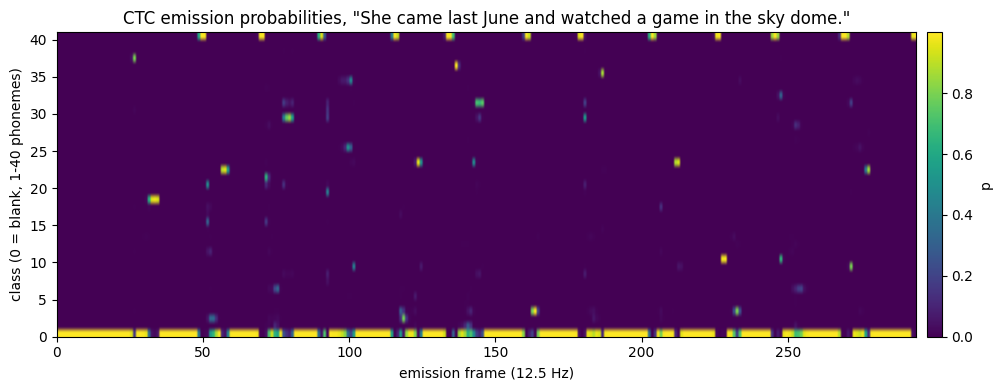

In [8]:
# longest val target
pick = max((val_ds[i] for i in range(len(val_ds))), key=lambda t: len(t.data["target"]))
b = collate([pick])
model.eval()
with torch.no_grad():
    logp, n_valid = model(normalized(b), b.lengths["neural"])
pred = greedy(logp[0], int(n_valid[0]))
ref = pick.data["target"].tolist()
print("sentence :", repr(pick.metadata["text"]))
print("true     :", VOCAB.decode(ref))
print("decoded  :", VOCAB.decode(pred))
print(f"PER      : {levenshtein(pred, ref) / len(ref):.3f}")

probs = logp[0, : int(n_valid[0])].exp().numpy()                       # (T', 41)
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(probs.T, aspect="auto", origin="lower", cmap="viridis",
               extent=[0, probs.shape[0], 0, 41])
ax.set(xlabel="emission frame (12.5 Hz)", ylabel="class (0 = blank, 1-40 phonemes)",
       title=f'CTC emission probabilities, "{pick.metadata["text"]}"')
fig.colorbar(im, ax=ax, label="p", pad=0.01)
plt.tight_layout()
plt.show()


## Notes

- PER from a small model trained on two sessions and scored on their published `val` blocks. It clears the empty baseline (1.0) but is far from usable transcription, which is expected at this scale.
- The partition is the authors' own. No block straddles train and val, but the source's rolling z-scoring window still crosses the boundary, so a val trial is not fully independent of its training neighbours.
- The `test` split carries no labels (the **Brain-to-Text '25** challenge set). It produces no `Sentence` trigger and so no segment here, but its neural streams are readable and usable as label-free inputs.
- **Brain-to-text vs. brain-to-voice:** the target here is a discrete, unaligned phoneme sequence (CTC), not a continuous aligned signal, so the segment is the whole trial and the target extractor is `PhonemeEncoder` rather than a regression series.
- Possible improvements include: using all 45 sessions, a deeper recurrent/transformer decoder, the paper's 5-gram/LLM (PER to WER), data augmentation, and per-session input normalization.
